In [1]:
# from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ds = load_dataset("Baliyang/SSU_data_dash")



In [2]:
df = pd.read_parquet("/home/dghtan/Projects/SSU-Data-Dash/data/listings.parquet")

In [3]:
pd.set_option('display.max_columns', None)

df.head()


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,0,0.0,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,0,0.0,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,1,0.0,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,1,0.0,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,1,0.0,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [48]:
#Checking the types of values certain columns have to understand what they represent

# df.groupby("house_type_name").apply(lambda sub_df: sub_df.dtypes)

# df.groupby("house_style").apply(lambda sub_df: sub_df.dtypes)

#df.groupby("lot_front").apply(lambda sub_df: sub_df.dtypes)


In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print(df.shape)
df.info()

(150000, 22)
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 22 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   ml_num                      150000 non-null  str           
 1   sold_price                  150000 non-null  float64       
 2   list_price                  150000 non-null  float64       
 3   date_listed                 150000 non-null  datetime64[us]
 4   date_sold                   150000 non-null  datetime64[us]
 5   days_on_market              150000 non-null  int64         
 6   house_type_name             150000 non-null  str           
 7   house_style                 150000 non-null  str           
 8   bedrooms                    150000 non-null  int64         
 9   washrooms                   150000 non-null  int64         
 10  parking_total               150000 non-null  int64         
 11  garage                      150000 no

Would like to invesitgate trends between each of the variables along with eachother and the response:

Pre guess:
Likely High trends:
- House style
- Bedrooms
- Washrooms
- House area
- Municipality
- Community

- Latitude/Longitude related to municipality

Somewhat trends
- Garage 
- Parking total
- lot front
- lot depth
- House type name

Other factors that are not given that are good indicators:
- Interest/Mortgage rates
- Job market/ employment


In [5]:
df["month_sold"] = df["date_sold"].dt.month
df["year_sold"] = df["date_sold"].dt.year

df["month_listed"] = df["date_listed"].dt.month
df["year_listed"] = df["date_listed"].dt.year


grouped_by_time = df.groupby(["bedrooms","year_sold", pd.cut(df["month_sold"], bins = np.arange(0, 13, 3))])["sold_price"].median()

grouped_by_time.head(100)


quarter_map = {
    pd.Interval(0, 3, closed='right'): 'Q1',
    pd.Interval(3, 6, closed='right'): 'Q2',
    pd.Interval(6, 9, closed='right'): 'Q3',
    pd.Interval(9, 12, closed='right'): 'Q4'
}
df['quarter'] = df['month_sold'].map(quarter_map)
df['time_range'] = df['year_sold'].astype(str) + " " + df['quarter'].astype(str)


# len(grouped_by_time)

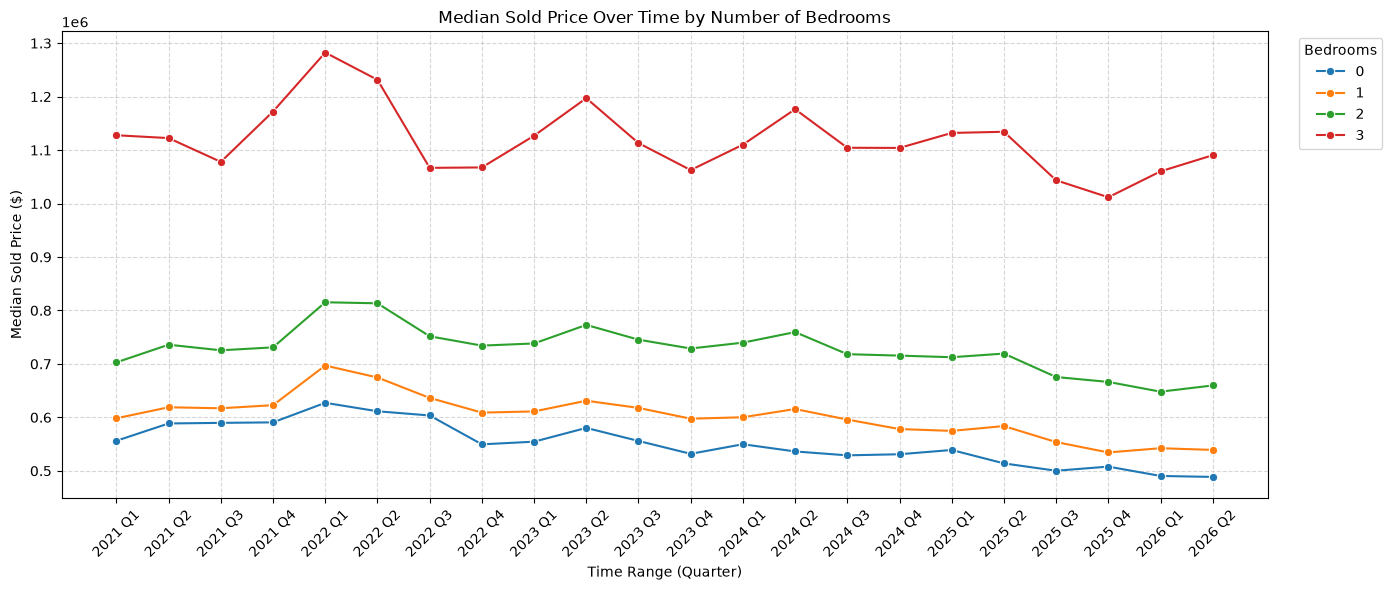

In [51]:
#Investigating how the number of bedrooms influence price over time (quartlerly)

# 1. Reset index so we have regular columns
plot_df = df
# 2. Map the 3-month bins (0, 3], (3, 6], etc. to Q1, Q2, Q3, Q4

plot_df = plot_df[plot_df["bedrooms"] < 4]
# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=plot_df,
    x='time_range',
    y='sold_price',
    hue='bedrooms',
    estimator="median",
    palette='tab10',
    marker='o',
    errorbar=None #Remove if want CI of true median
)
plt.title('Median Sold Price Over Time by Number of Bedrooms')
plt.xlabel('Time Range (Quarter)')
plt.ylabel('Median Sold Price ($)')
plt.xticks(rotation=45)
plt.legend(title='Bedrooms', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

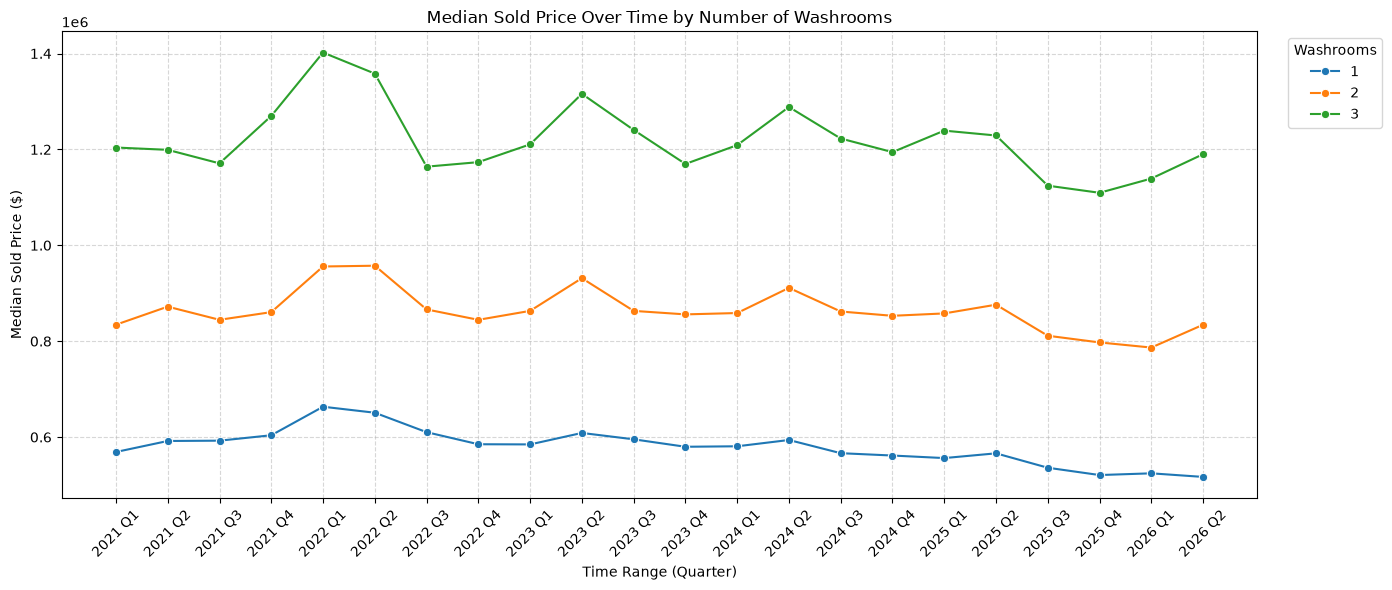

In [52]:
#Investigating how the number of wahsrooms influence price over time (quartlerly)

# 1. Reset index so we have regular columns
plot_df = df
# 2. Map the 3-month bins (0, 3], (3, 6], etc. to Q1, Q2, Q3, Q4

plot_df = plot_df[plot_df["washrooms"] < 4]

# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=plot_df,
    x='time_range',
    y='sold_price',
    hue='washrooms',
    estimator="median",
    palette='tab10',
    marker='o',
    errorbar=None #Remove if want CI of true median
)
plt.title('Median Sold Price Over Time by Number of Washrooms')
plt.xlabel('Time Range (Quarter)')
plt.ylabel('Median Sold Price ($)')
plt.xticks(rotation=45)
plt.legend(title='Washrooms', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

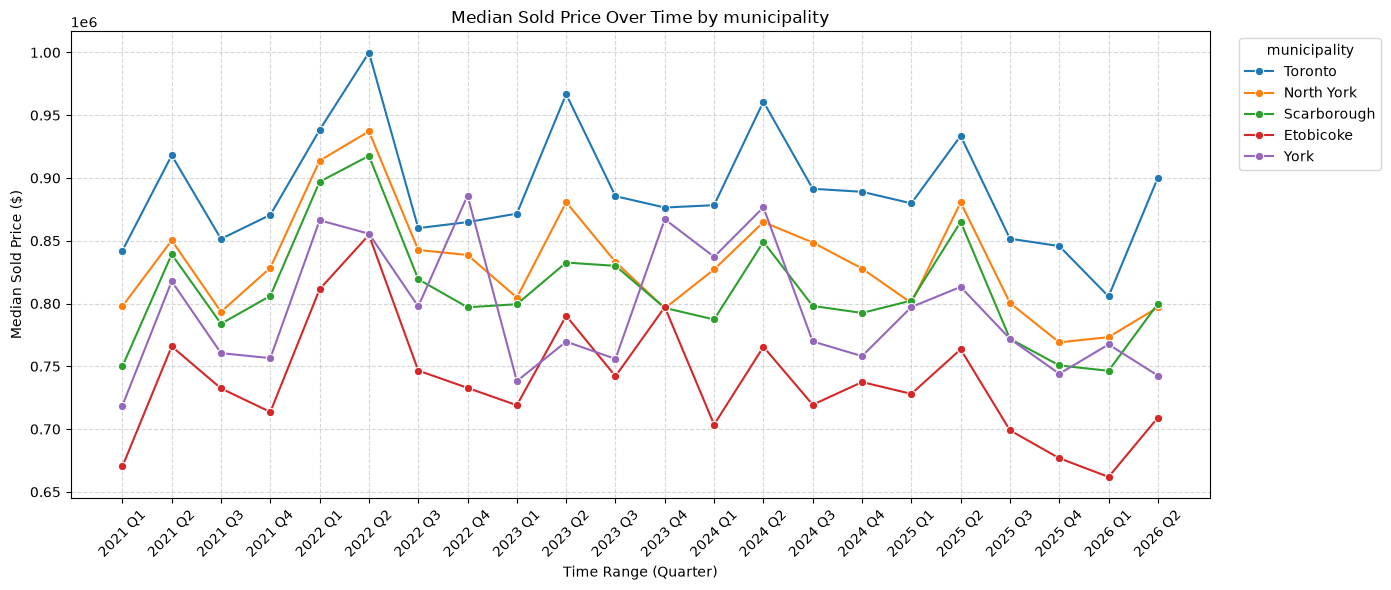

In [53]:
#Investigating how the municipality(general location) influence price over time (quartlerly)

# 1. Reset index so we have regular columns
plot_df = df
# 2. Map the 3-month bins (0, 3], (3, 6], etc. to Q1, Q2, Q3, Q4

# plot_df = plot_df[plot_df["washrooms"] < 4]

# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=plot_df,
    x='time_range',
    y='sold_price',
    hue='municipality',
    estimator="median",
    palette='tab10',
    marker='o',
    errorbar=None #Remove if want CI of true median
)
plt.title('Median Sold Price Over Time by municipality')
plt.xlabel('Time Range (Quarter)')
plt.ylabel('Median Sold Price ($)')
plt.xticks(rotation=45)
plt.legend(title='municipality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [6]:
len(df.groupby("community"))

#Might not want to 

145

In [55]:
#Investigating how the municipality(general location) influence price over time (quartlerly)

# 1. Reset index so we have regular columns
plot_df = df
# 2. Map the 3-month bins (0, 3], (3, 6], etc. to Q1, Q2, Q3, Q4

# plot_df = plot_df[plot_df["washrooms"] < 4]

# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
# plt.figure(figsize=(14, 6))
# sns.lineplot(
#     data=plot_df,
#     x='time_range',
#     y='sold_price',
#     hue='community',
#     estimator="median",
#     palette='tab10',
#     marker='o',
#     errorbar=None #Remove if want CI of true median
# )
# plt.title('Median Sold Price Over Time by community')
# plt.xlabel('Time Range (Quarter)')
# plt.ylabel('Median Sold Price ($)')
# plt.xticks(rotation=45)
# plt.legend(title='community', bbox_to_anchor=(1.02, 1), loc='upper left')
# plt.grid(True, linestyle='--', alpha=0.5)
# plt.tight_layout()
# plt.show()

In [56]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_price_heatmap(
    df, year, month=None, lat_bins=35, lon_bins=35, figsize=(11, 8)
):
    """Plots a 2D spatial heatmap of median sold prices across latitude & longitude

    for a specified year (and optional month).

    Parameters:
    -----------
    df : pd.DataFrame
        Listings dataframe containing 'date_sold', 'sold_price', 'latitude',
        'longitude'.
    year : int
        The year to filter (e.g., 2022).
    month : int, optional
        The month to filter (1-12). If None, filters the whole year.
    lat_bins : int, default 35
        Number of grid bins along latitude (Y-axis).
    lon_bins : int, default 35
        Number of grid bins along longitude (X-axis).
    figsize : tuple, default (11, 8)
        Matplotlib figure size.
    """
    # 1. Ensure date_sold is datetime
    if not pd.api.types.is_datetime64_any_dtype(df["date_sold"]):
        date_series = pd.to_datetime(df["date_sold"])
    else:
        date_series = df["date_sold"]

    # 2. Slice the dataframe for the specified time range
    mask = date_series.dt.year == year
    time_label = f"{year}"
    if month is not None:
        mask = mask & (date_series.dt.month == month)
        month_name = pd.Timestamp(year=year, month=month, day=1).strftime("%B")
        time_label = f"{month_name} {year}"

    subset = df.loc[mask, ["latitude", "longitude", "sold_price"]].dropna()

    if subset.empty:
        print(f"No transactions found for {time_label}.")
        return

    # 3. Discretize latitude and longitude into 2D grid bins
    # Label each bin by its midpoint for readable axis ticks
    lat_cut, lat_edges = pd.cut(
        subset["latitude"], bins=lat_bins, retbins=True
    )
    lon_cut, lon_edges = pd.cut(
        subset["longitude"], bins=lon_bins, retbins=True
    )

    subset["lat_bin"] = lat_cut.apply(lambda b: round((b.left + b.right) / 2, 3))
    subset["lon_bin"] = lon_cut.apply(lambda b: round((b.left + b.right) / 2, 3))

    # 4. Compute median sold_price per grid cell & pivot into a 2D matrix
    heatmap_matrix = subset.pivot_table(
        index="lat_bin",
        columns="lon_bin",
        values="sold_price",
        aggfunc="median",
    )

    # Invert Y-axis so higher latitudes appear at the top (geographical north)
    heatmap_matrix = heatmap_matrix.sort_index(ascending=False)

    # 5. Plot the heatmap
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        heatmap_matrix,
        cmap="viridis",
        cbar_kws={
            "label": "Median Sold Price ($)",
            "format": "${x:,.0f}",
        },
        linewidths=0.2,
        linecolor="white",
        ax=ax,
    )

    ax.set_title(
        f"Geographic Median Sold Price Heatmap ({time_label})",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    ax.set_xlabel("Longitude (°W)", fontsize=11)
    ax.set_ylabel("Latitude (°N)", fontsize=11)

    # Reduce tick label density for readability
    xticks = ax.get_xticks()
    yticks = ax.get_yticks()
    ax.set_xticks(xticks[:: max(1, len(xticks) // 8)])
    ax.set_yticks(yticks[:: max(1, len(yticks) // 8)])

    plt.tight_layout()
    plt.show()

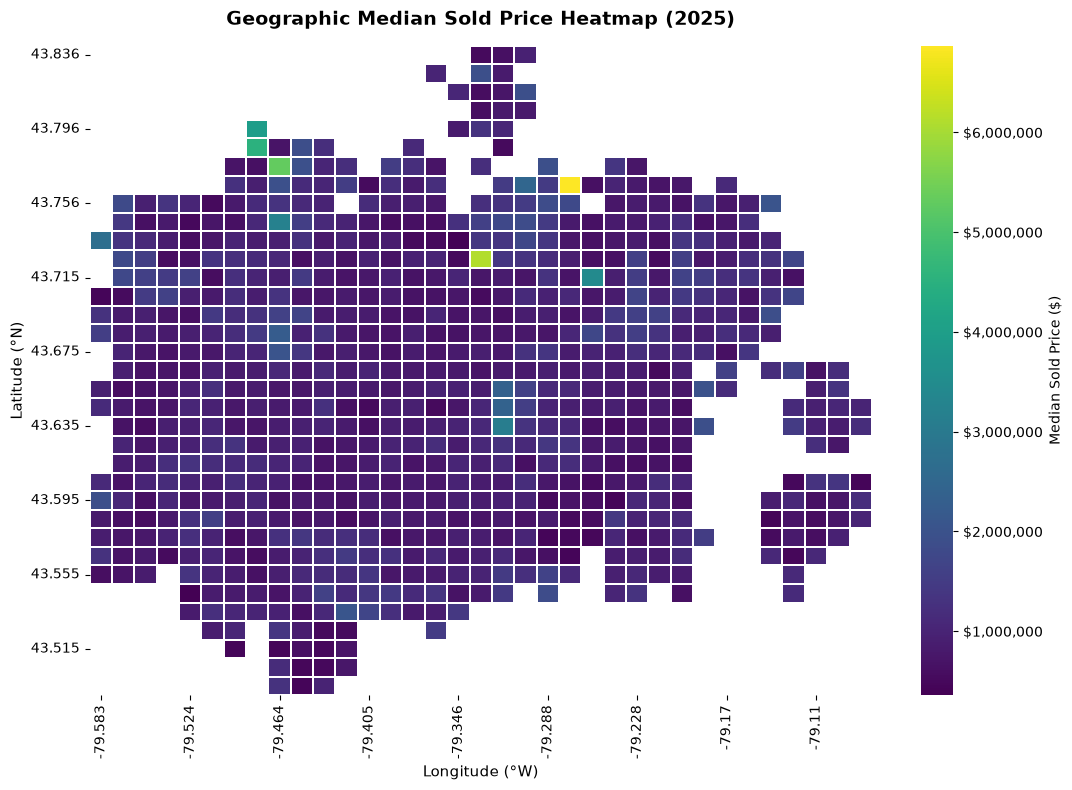

In [57]:
# plot_price_heatmap(df, year=2022, month = 5)
plot_price_heatmap(df, year=2025)


In [58]:
def get_median(text):
    if "-" in text:
        split_parts = text.split("-")
        median_val = (float(split_parts[0]) + float(split_parts[1])) /2 
    else:
        median_val = float(text)
    return float(median_val)

df["median_house_area"] = df["house_area"].apply(get_median)

df.head(3)



,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks,month_sold,year_sold,quarter,time_range,median_house_area
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,0,0.0,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...,1,2021,Q1,2021 Q1,622.0
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,0,0.0,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher...",1,2021,Q1,2021 Q1,649.0
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,1,0.0,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo...",1,2021,Q1,2021 Q1,999.5


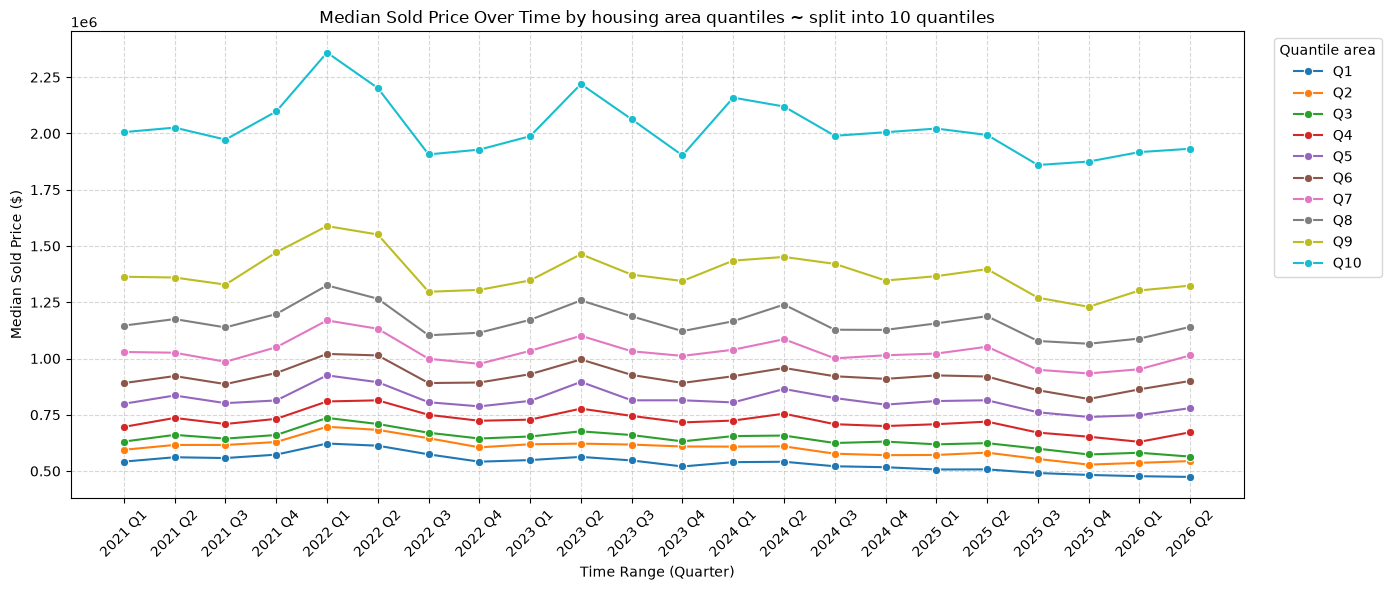

In [59]:
#Investigating how housing area influences price over time (quartlerly)

# 1. Reset index so we have regular columns
plot_df = df
# 2. Map the 3-month bins (0, 3], (3, 6], etc. to Q1, Q2, Q3, Q4

# plot_df = plot_df[plot_adf["washrooms"] < 4]

# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=plot_df,
    x='time_range',
    y='sold_price',
    hue= pd.qcut(plot_df["median_house_area"], q=10, labels=['Q1', 'Q2', 'Q3', 'Q4','Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']),
    estimator="median",
    palette='tab10',
    marker='o',
    errorbar=None #Remove if want CI of true median
)
plt.title('Median Sold Price Over Time by housing area quantiles ~ split into 10 quantiles')
plt.xlabel('Time Range (Quarter)')
plt.ylabel('Median Sold Price ($)')
plt.xticks(rotation=45)
plt.legend(title='Quantile area', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [60]:
#Investigating null lot sizes (front and back)


zero_lot_front_area = len(df[df["lot_front"] == 0])


zero_lot_depth_area = len(df[df["lot_depth"] == 0])

print(f"{zero_lot_front_area} AND {zero_lot_depth_area}")

#No lots with zero front and depth
#Can we assume null means no lot?



0 AND 0


In [9]:
df["lot_front"] = np.where(df["lot_front"].isnull(), 0, df["lot_front"])
df["lot_depth"] = np.where(df["lot_depth"].isnull(), 0, df["lot_depth"])

zero_lot_front_area = len(df[df["lot_front"] == 0])


zero_lot_depth_area = len(df[df["lot_depth"] == 0])

print(f"{zero_lot_front_area} AND {zero_lot_depth_area}")

# lot_sum_df = df.groupby("house_style")["lot_front"].sum()
lot_sum_df = df.groupby("house_style")["lot_depth"].sum()

lot_sum_df.head(20)

87263 AND 87263


house_style
1 1/2 Storey        276882.33
1 Storey/Apt             0.00
2 1/2 Storey        373768.94
2-Storey           3759655.90
3-Storey            642509.90
Apartment                0.00
Backsplit 3         100430.29
Backsplit 4         167672.07
Backsplit 5          36435.64
Bungalow           1645160.96
Bungalow-Raised     297583.40
Loft                     0.00
Multi-Level              0.00
Sidesplit 3          70578.57
Sidesplit 4         116005.36
Stacked Townhse          0.00
Name: lot_depth, dtype: float64

/tmp/ipykernel_1270012/3216717671.py:12: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(
/tmp/ipykernel_1270012/3216717671.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Quantile area', bbox_to_anchor=(1.02, 1), loc='upper left')


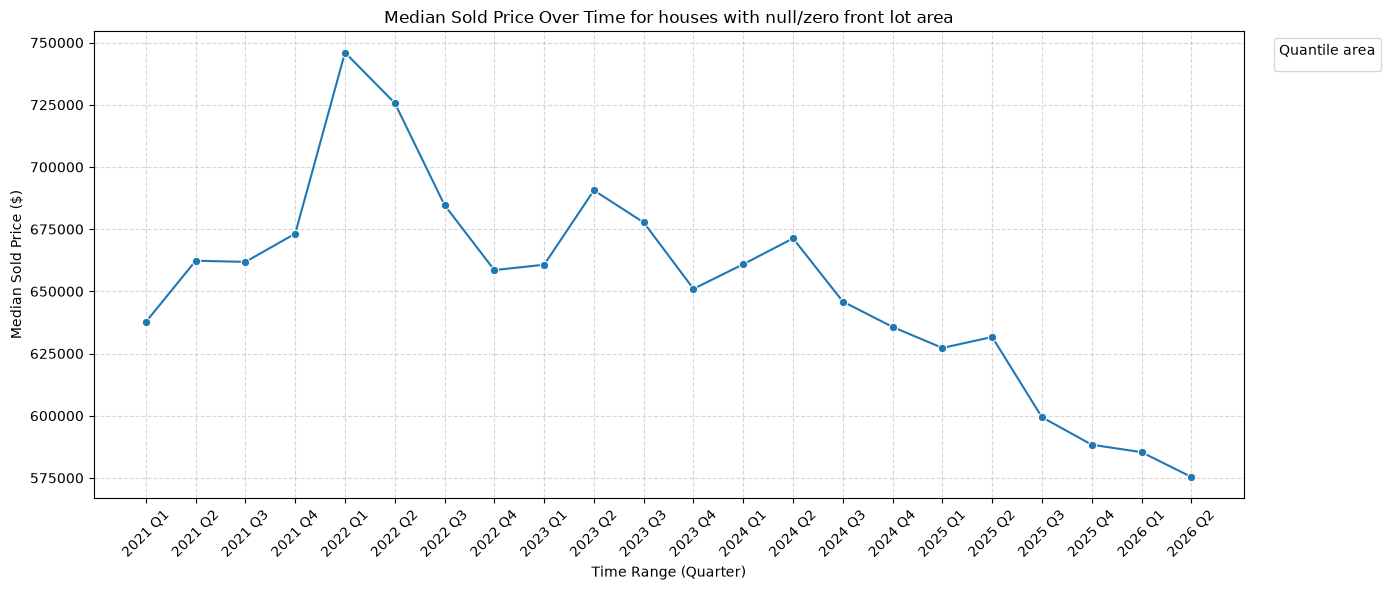

In [62]:
df_zero_lot_front = df[df["lot_front"] == 0]

#Investigating how zero front plot area influences price over time (quartlerly)

# 1. Reset index so we have regular columns
plot_df = df_zero_lot_front

# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=plot_df,
    x='time_range',
    y='sold_price',
    estimator="median",
    palette='tab10',
    marker='o',
    errorbar=None #Remove if want CI of true median
)
plt.title('Median Sold Price Over Time for houses with null/zero front lot area')
plt.xlabel('Time Range (Quarter)')
plt.ylabel('Median Sold Price ($)')
plt.xticks(rotation=45)
plt.legend(title='Quantile area', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

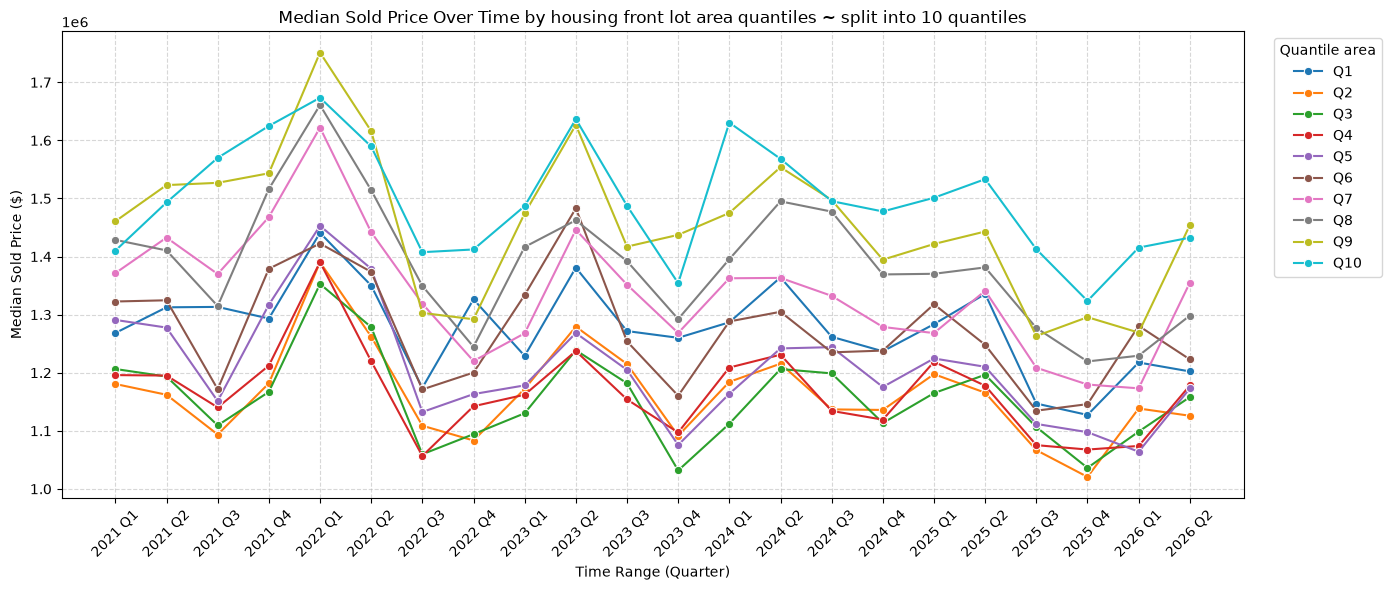

In [63]:
df_more_than_zero_lot_front = df[df["lot_front"] > 0]

#Investigating how front plot area influences price over time (quartlerly)

plot_df = df_more_than_zero_lot_front

# plot_df = plot_df[plot_adf["washrooms"] < 4]

# 3. Sort chronologically
plot_df = plot_df.sort_values(by=['year_sold', 'month_sold'])
# 4. Plot using Seaborn
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=plot_df,
    x='time_range',
    y='sold_price',
    hue= pd.qcut(plot_df["lot_front"], q=10, labels=['Q1', 'Q2', 'Q3', 'Q4','Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']),
    estimator="median",
    palette='tab10',
    marker='o',
    errorbar=None #Remove if want CI of true median
)
plt.title('Median Sold Price Over Time by housing front lot area quantiles ~ split into 10 quantiles')
plt.xlabel('Time Range (Quarter)')
plt.ylabel('Median Sold Price ($)')
plt.xticks(rotation=45)
plt.legend(title='Quantile area', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Houses that have a front lot area have a signifigant increase in pricing compared to houses with null/0 lot front area. Although it does not seem the lot area influences the pricing compared to houses with lot areas (Q1 = 10% lowest area is consitently more than Q2,Q3,Q4)

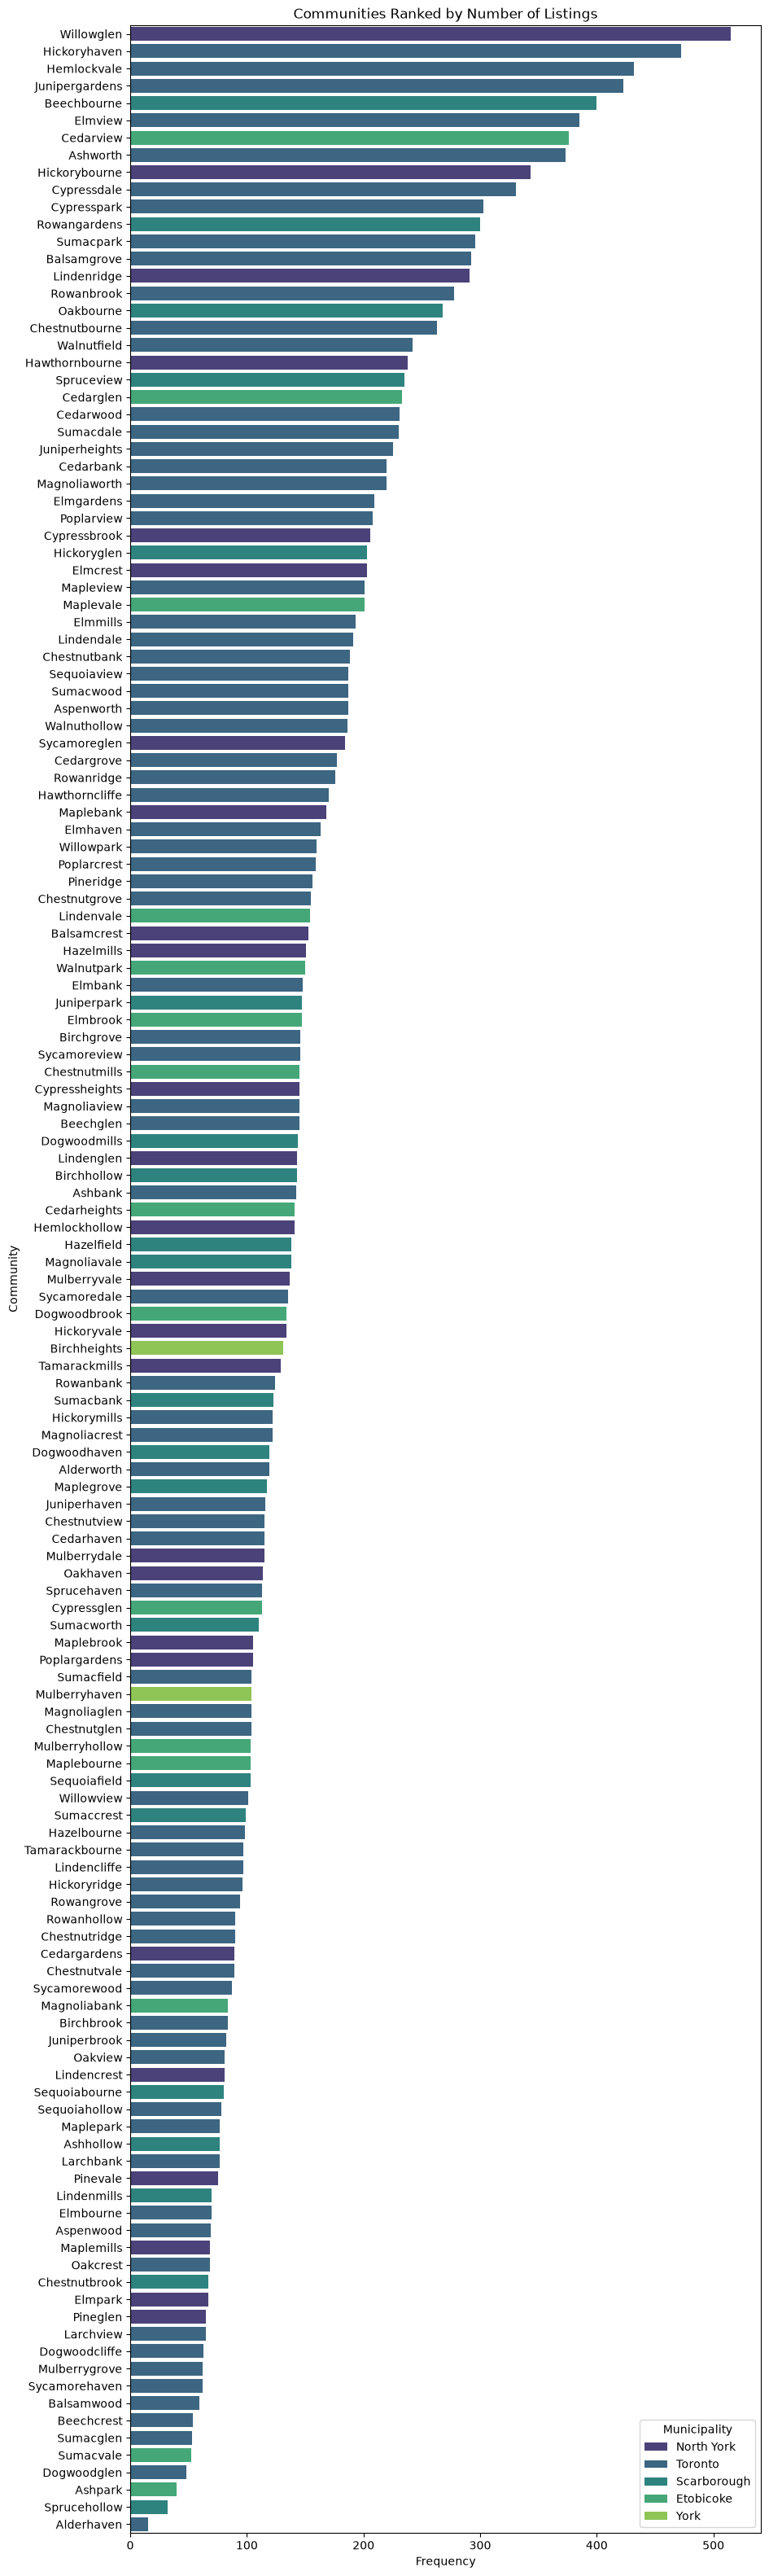

In [64]:
# plot_df = df[df["municipality"] == "Toronto"].groupby('community').count()

# plot_df.head()
# plt.figure(figsize=(14, 6))
# sns.countplot(
#     data = plot_df,
#     x = 'community',
# )
# plt.show()
target_year = 2025


year_df = df[df["year_sold"] == target_year]
# Get all community counts sorted from highest to lowest frequency
community_counts = year_df['community'].value_counts()

# Use standard Python slicing: [20:40] grabs the 21st through 40th items (zero-indexed)
ranged_communities = community_counts.index[0:151]

# Filter the dataframe to only include those specific communities
df_tier_2 = year_df[year_df['community'].isin(ranged_communities)]

# Plot using a Horizontal Bar Chart
plt.figure(figsize=(10, 40))
sns.countplot(
    data=df_tier_2, 
    y='community', 
    order=ranged_communities, # Ensures the bars are plotted in the correct ranked order
    palette='viridis',
    hue = "municipality"
)
plt.title("Communities Ranked by Number of Listings")
plt.xlabel("Frequency")
plt.ylabel("Community")
plt.legend(title = "Municipality")
plt.show()

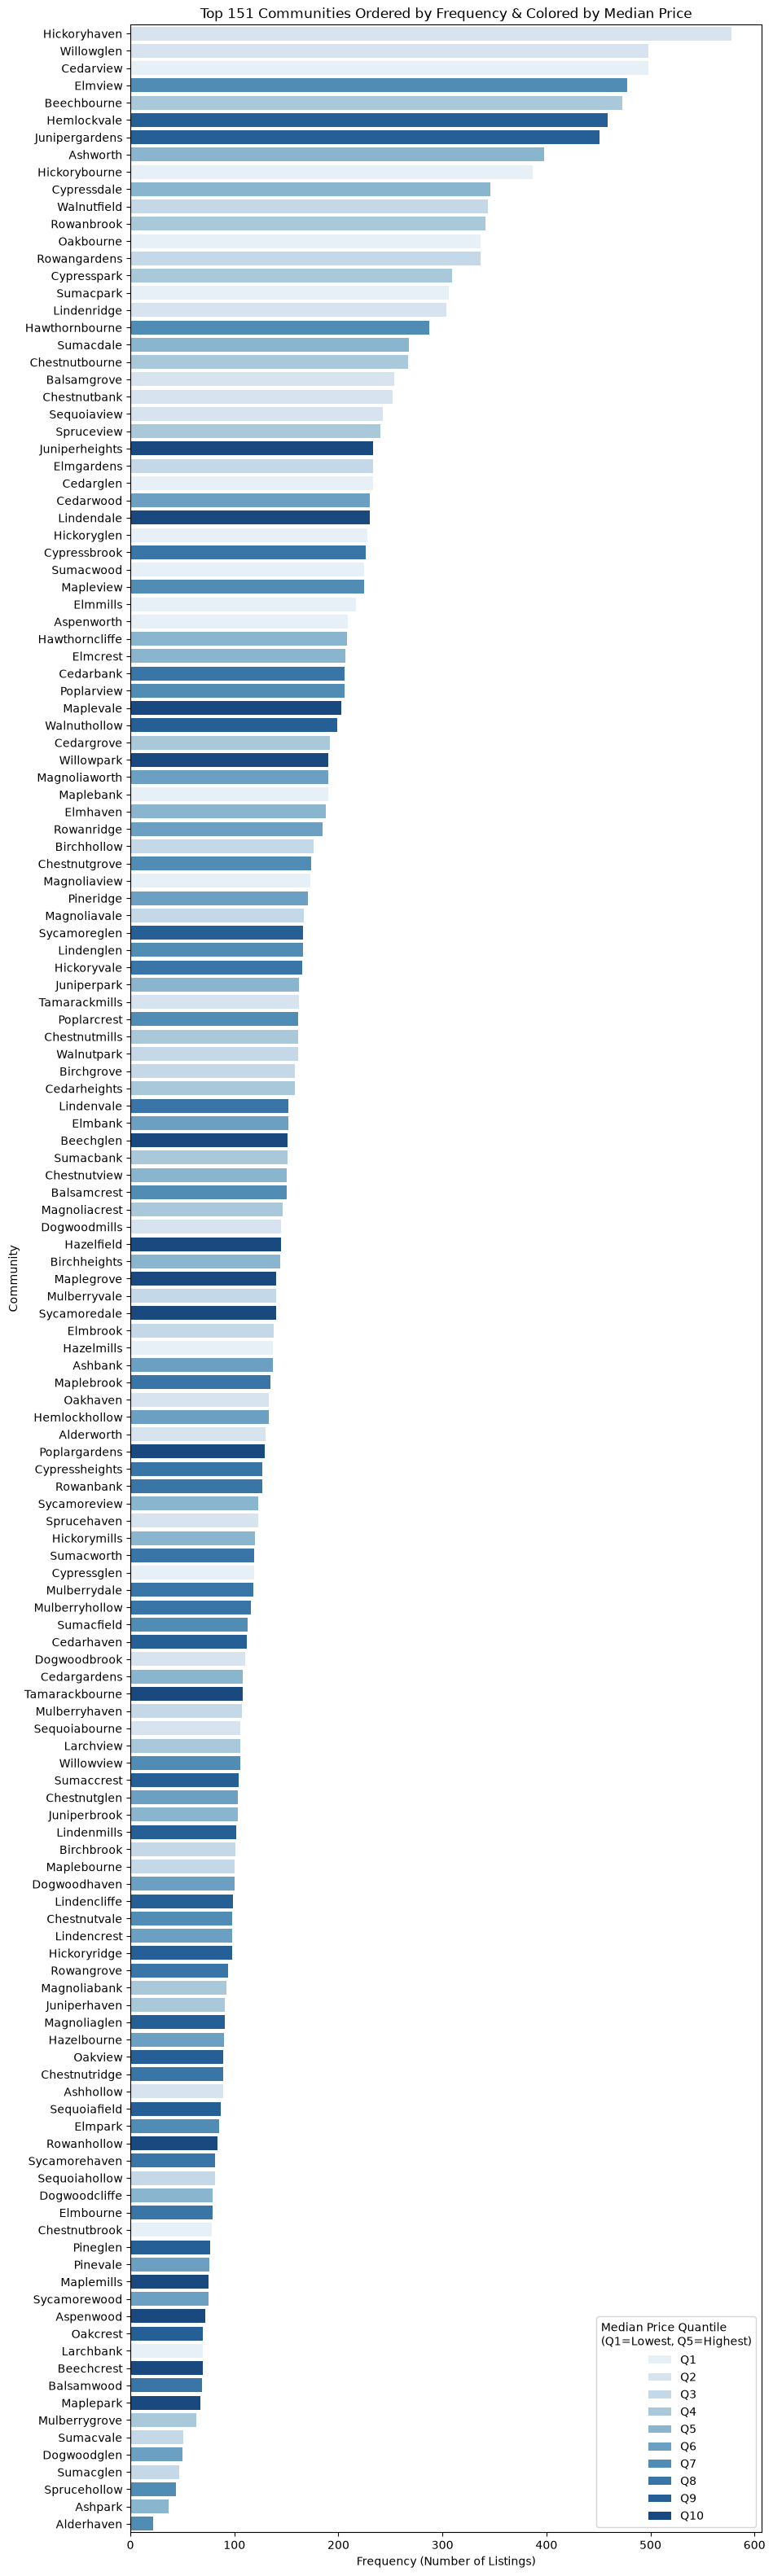

In [65]:
target_year = 2024
# 1. Filter for the target year
year_df = df[df["year_sold"] == target_year].copy()

# 2. Get the top 151 communities by frequency (this automatically sorts highest to lowest frequency)
top_communities_freq = year_df['community'].value_counts().index[0:151]
df_tier_2 = year_df[year_df['community'].isin(top_communities_freq)].copy()

# 3. Calculate median sold_price for each community to determine price bins
community_medians = df_tier_2.groupby('community')['sold_price'].median()

# 4. Create the quantile bins (e.g., 5 quantiles)
num_quantiles = 10
quantile_labels = [f'Q{i}' for i in range(1, num_quantiles + 1)] # Q1 (lowest) to Q5 (highest)

# Use qcut to divide the medians into equal-sized quantile bins
community_bins = pd.qcut(community_medians, q=num_quantiles, labels=quantile_labels)

# Map these quantile labels back to the main dataframe
df_tier_2['price_quantile'] = df_tier_2['community'].map(community_bins)

# 5. Plot the data
plt.figure(figsize=(10, 40))

sns.countplot(
    data=df_tier_2, 
    y='community', 
    order=top_communities_freq,  # <-- CHANGED: Y-axis is now ordered by frequency
    hue='price_quantile',        # <-- STILL colors by the median price quantile
    hue_order=quantile_labels,   # Ensures legend and colors go in order (Q1 to Q5)
    palette='Blues',             # Q1 is light, Q5 is dark
    dodge=False                  # Prevents Seaborn from drawing thin, split bars
)

plt.title("Top 151 Communities Ordered by Frequency & Colored by Median Price")
plt.xlabel("Frequency (Number of Listings)")
plt.ylabel("Community")
plt.legend(title="Median Price Quantile\n(Q1=Lowest, Q5=Highest)")
plt.show()

In [15]:
df.head()

,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks,month_sold,year_sold,quarter,time_range,month_listed,year_listed
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,0,0.0,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...,1,2021,Q1,2021 Q1,12,2020
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,0,0.0,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher...",1,2021,Q1,2021 Q1,12,2020
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,1,0.0,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo...",1,2021,Q1,2021 Q1,12,2020
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,1,0.0,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...,1,2021,Q1,2021 Q1,12,2020
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,1,0.0,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s...",1,2021,Q1,2021 Q1,12,2020


In [27]:
cutoff = pd.to_datetime("2026-04-01")
train = df[df["date_listed"] < cutoff]
val = df[df["date_listed"] >= cutoff]
print(f"{len(train)}  AND {len(val)}")

147256  AND 2744


In [ ]:
#Testing out tf-idf
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# 1. Initialize the vectorizer
# max_features limits it to the top 100 most important words so your dataset doesn't explode
# stop_words='english' automatically removes filler words like "the", "and", "is"
tfidf = TfidfVectorizer(max_features=100, stop_words='english')

# 2. Fit and transform the remarks column (ensure you fill NaN values with empty strings first)
remarks_clean = df["remarks"].fillna("")
tfidf_matrix = tfidf.fit_transform(remarks_clean)

# 3. Create a DataFrame of the new TF-IDF features to attach to your main X DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(), 
    columns=[f"tfidf_{word}" for word in tfidf.get_feature_names_out()],
    index=df.index
)

# --- HOW TO SEE THE RAREST WORDS ---
# The .idf_ attribute stores the rarity score of each word across the whole dataset
word_rarity = pd.DataFrame({
    'word': tfidf.get_feature_names_out(),
    'idf_score': tfidf.idf_
})

# Sort by highest IDF score to see the rarest, most highly weighted terms


In [11]:
print(word_rarity.sort_values(by='idf_score', ascending=False).head(40))

           word  idf_score
60         near   3.387859
23         come   3.385394
96      updated   3.373587
91    townhouse   3.324974
5      backyard   3.321571
99        young   3.318044
1           add   3.311633
55      located   3.300195
18        cared   3.292509
35     fixtures   3.284163
2          adds   3.274069
15        buyer   3.254754
22       closet   3.248735
14     bungalow   3.232506
67        older   3.230767
64        newer   3.216414
95         unit   3.187717
28     detached   3.178076
45     hardwood   3.177664
79  restaurants   3.173144
59       modern   3.170804
19       centre   3.164106
17        cafes   3.153253
56      looking   3.151704
9           bed   3.149699
52      library   3.148555
98      worship   3.132062
29     downtown   3.124501
74       places   3.124111
25      commute   3.118993
76       ravine   3.114399
88       stores   3.111696
16       buyers   3.109220
44      grocery   3.107244
82        shops   3.100577
46      highway   3.098726
8